# 03. Exploratory Data Analysis: Parque Natural de Montesinho Wildfire Cohort (2004–2025)

## Section 1: Environment Setup and Relative Path Configuration


In [1]:
# Import standard library modules
import json
import warnings
from pathlib import Path

# Import core data analysis and visualization libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as MplPolygon

# Suppress non-critical future warnings for clean notebook output
warnings.filterwarnings("ignore", category=FutureWarning)

# Configure pandas display formatting for readable tables
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 1000)
pd.set_option("display.precision", 3)

# Configure matplotlib visual appearance
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.edgecolor"] = "#CCCCCC"
plt.rcParams["axes.linewidth"] = 0.8

# Define self-contained relative paths from the project working directory
DATA_PATH = Path("data/interim/icnf_sgif/montesinho_events_2004_2025_audited.csv")
BOUNDARY_PATH = Path("data/reference/icnf_sgif/montesinho_boundary/montesinho_boundary_epsg3763.geojson")
TABLE_DIR = Path("reports/tables/icnf_sgif")
FIGURE_DIR = Path("reports/figures/icnf_sgif")

# Create output directories if they do not already exist
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Define consistent academic color palette
NAVY = "#17324D"
BLUE = "#2878B5"
ORANGE = "#F28E2B"
RED = "#D1495B"
GREEN = "#2A9D8F"
GREY = "#6B7280"

print("Environment configured successfully using relative paths:")
print(f" - Audited cohort input : {DATA_PATH.as_posix()}")
print(f" - Official boundary    : {BOUNDARY_PATH.as_posix()}")
print(f" - Report tables folder : {TABLE_DIR.as_posix()}")
print(f" - Report figures folder: {FIGURE_DIR.as_posix()}")


Environment configured successfully using relative paths:
 - Audited cohort input : data/interim/icnf_sgif/montesinho_events_2004_2025_audited.csv
 - Official boundary    : data/reference/icnf_sgif/montesinho_boundary/montesinho_boundary_epsg3763.geojson
 - Report tables folder : reports/tables/icnf_sgif
 - Report figures folder: reports/figures/icnf_sgif


## Section 2: Loading the Audited Cohort & Data Quality Verification


In [2]:
# Load the audited Montesinho cohort from Notebook 02
df = pd.read_csv(DATA_PATH, low_memory=False)

# Parse alert, first-intervention, and extinction timestamps into datetime objects
datetime_columns = [
    "DataHoraAlerta",
    "DataHora_PrimeiraIntervencao",
    "DataHora_Extincao",
]
for column_name in datetime_columns:
    df[column_name] = pd.to_datetime(df[column_name], errors="coerce")

# Define the 7 Canadian Fire Weather Index (FWI) columns
fwi_features = ["FFMC", "DMC", "DC", "ISI", "BUI", "FWI", "DSR"]

# Step-by-step verification of data quality checks
total_rows = len(df)
unique_sgif_ids = df["Codigo_SGIF"].nunique()
duplicate_id_count = int(df.duplicated("Codigo_SGIF").sum())
negative_target_count = int((df["AreaTotal_ha"] < 0).sum())

# Check difference between AreaTotal_ha and sum of vegetation sub-areas
component_sum = df["AreaPov_ha"] + df["AreaMato_ha"] + df["AreaAgric_ha"]
component_diff = (df["AreaTotal_ha"] - component_sum).abs()
disagreement_count = int((component_diff > 0.011).sum())

# Check FWI physical bounds (all indices >= 0, and FFMC <= 101)
invalid_fwi_count = 0
for index, row in df.iterrows():
    row_has_invalid_fwi = False
    for fwi_col in fwi_features:
        val = row[fwi_col]
        if pd.notna(val) and float(val) < 0.0:
            row_has_invalid_fwi = True
    if pd.notna(row["FFMC"]) and float(row["FFMC"]) > 101.0:
        row_has_invalid_fwi = True
    if row_has_invalid_fwi:
        invalid_fwi_count += 1

# Identify rows missing one or more FWI fields and map them to chronological splits
missing_fwi_mask = df[fwi_features].isna().any(axis=1)
missing_fwi_count = int(missing_fwi_mask.sum())

missing_fwi_records = []
for index, row in df[missing_fwi_mask].iterrows():
    year_val = int(row["Ano"])
    if year_val <= 2017:
        split_name = "Train (2004-2017)"
    elif year_val <= 2021:
        split_name = "Validation (2018-2021)"
    else:
        split_name = "Protected Test (2022-2025)"

    missing_fwi_records.append({
        "Codigo_SGIF": row["Codigo_SGIF"],
        "Ano": year_val,
        "Chronological_Split": split_name,
        "AreaTotal_ha": float(row["AreaTotal_ha"]),
        "Missing_FWI_Fields": int(row[fwi_features].isna().sum()),
    })

missing_fwi_df = pd.DataFrame(missing_fwi_records)

print("======================================================================")
print("COHORT & DATA QUALITY VERIFICATION SUMMARY")
print("======================================================================")
print(f"Core Official-Boundary Events (2004-2025) : {total_rows:,}")
print(f"Total Columns (41 Raw + 12 Audit Flags)   : {df.shape[1]}")
print(f"Unique Codigo_SGIF Identifiers            : {unique_sgif_ids:,}")
print(f"Duplicate SGIF ID Rows                    : {duplicate_id_count}")
print(f"Negative Target Rows (< 0 ha)             : {negative_target_count}")
print(f"Area-Component Disagreements (> 0.011 ha) : {disagreement_count}")
print(f"Invalid FWI Range Rows                    : {invalid_fwi_count}")
print(f"Rows Missing FWI Fields                   : {missing_fwi_count}")
print(f"Cumulative Burned Area (2004-2025)        : {df['AreaTotal_ha'].sum():,.2f} ha")
print("======================================================================")
print()
print("Traceability of Records Missing FWI Fields:")
display(missing_fwi_df)


COHORT & DATA QUALITY VERIFICATION SUMMARY
Core Official-Boundary Events (2004-2025) : 1,644
Total Columns (41 Raw + 12 Audit Flags)   : 53
Unique Codigo_SGIF Identifiers            : 1,644
Duplicate SGIF ID Rows                    : 0
Negative Target Rows (< 0 ha)             : 0
Area-Component Disagreements (> 0.011 ha) : 0
Invalid FWI Range Rows                    : 0
Rows Missing FWI Fields                   : 3
Cumulative Burned Area (2004-2025)        : 16,203.98 ha

Traceability of Records Missing FWI Fields:


,Codigo_SGIF,Ano,Chronological_Split,AreaTotal_ha,Missing_FWI_Fields
0,TM21375,2013,Train (2004-2017),0.950,7
1,TM219507,2019,Validation (2018-2021),0.032,7
2,2022_04_0009908,2022,Protected Test (2022-2025),1.000,7


## Section 3: Target Variable (`AreaTotal_ha`) Summary Statistics


In [3]:
# Ensure AreaTotal_ha is numeric and compute the log1p-transformed target
area_ha = pd.to_numeric(df["AreaTotal_ha"], errors="coerce")
df["_log1p_area"] = np.log1p(area_ha)

# Count zero-area micro-fires and large fires using simple step-by-step conditions
zero_area_count = int((area_ha == 0).sum())
zero_area_pct = (zero_area_count / len(df)) * 100.0

fires_100_to_500_count = int(((area_ha >= 100.0) & (area_ha < 500.0)).sum())
fires_ge_500_count = int((area_ha >= 500.0).sum())
fires_ge_100_count = int((area_ha >= 100.0).sum())
fires_ge_100_pct = (fires_ge_100_count / len(df)) * 100.0

# Build the target summary table for reports/tables/icnf_sgif/eda_target_summary.csv
target_summary_rows = [
    {"metric": "records", "value": float(len(df))},
    {"metric": "minimum_ha", "value": float(area_ha.min())},
    {"metric": "q1_ha", "value": float(area_ha.quantile(0.25))},
    {"metric": "median_ha", "value": float(area_ha.median())},
    {"metric": "mean_ha", "value": float(area_ha.mean())},
    {"metric": "q3_ha", "value": float(area_ha.quantile(0.75))},
    {"metric": "p90_ha", "value": float(area_ha.quantile(0.90))},
    {"metric": "p95_ha", "value": float(area_ha.quantile(0.95))},
    {"metric": "p99_ha", "value": float(area_ha.quantile(0.99))},
    {"metric": "maximum_ha", "value": float(area_ha.max())},
    {"metric": "std_ha", "value": float(area_ha.std())},
    {"metric": "skewness", "value": float(area_ha.skew())},
    {"metric": "zero_area_records", "value": float(zero_area_count)},
    {"metric": "fires_ge_100ha", "value": float(fires_ge_100_count)},
    {"metric": "fires_ge_500ha", "value": float(fires_ge_500_count)},
]

target_summary = pd.DataFrame(target_summary_rows)
target_summary_path = TABLE_DIR / "eda_target_summary.csv"
target_summary.to_csv(target_summary_path, index=False)

print("======================================================================")
print("TARGET VARIABLE (AreaTotal_ha) SUMMARY STATISTICS")
print("======================================================================")
print(f"Core Official-Boundary Events : {len(df):,}")
print(f"Median Burned Area            : {area_ha.median():.2f} ha")
print(f"Mean Burned Area              : {area_ha.mean():.3f} ha")
print(f"Maximum Burned Area           : {area_ha.max():,.2f} ha")
print(f"Standard Deviation            : {area_ha.std():.3f} ha")
print(f"Raw Skewness                  : {area_ha.skew():.3f}")
print(f"Log1p Skewness                : {df['_log1p_area'].skew():.3f}")
print(f"Zero-Area Events (0 ha)       : {zero_area_count} events ({zero_area_pct:.2f}%)")
print(
    f"Large Fires (>= 100 ha)       : {fires_ge_100_count} events ({fires_ge_100_pct:.2f}%) "
    f"[{fires_100_to_500_count} in 100 to <500 ha, {fires_ge_500_count} in >=500 ha]"
)
print(f"Saved summary table to        : {target_summary_path.as_posix()}")
print("======================================================================")
print()
display(target_summary)


TARGET VARIABLE (AreaTotal_ha) SUMMARY STATISTICS
Core Official-Boundary Events : 1,644
Median Burned Area            : 1.00 ha
Mean Burned Area              : 9.856 ha
Maximum Burned Area           : 1,057.50 ha
Standard Deviation            : 54.961 ha
Raw Skewness                  : 13.055
Log1p Skewness                : 1.708
Zero-Area Events (0 ha)       : 19 events (1.16%)
Large Fires (>= 100 ha)       : 31 events (1.89%) [26 in 100 to <500 ha, 5 in >=500 ha]
Saved summary table to        : reports/tables/icnf_sgif/eda_target_summary.csv



,metric,value
0,records,1644.000
1,minimum_ha,0.000
2,q1_ha,0.221
3,median_ha,1.000
4,mean_ha,9.856
5,q3_ha,4.000
6,p90_ha,13.000
7,p95_ha,29.316
8,p99_ha,192.817
9,maximum_ha,1057.500


## Section 4: Visualization 1 - Raw vs. Log1p Target Distribution


Saved side-by-side target distribution figure to: reports/figures/icnf_sgif/burned_area_log1p_distribution.png


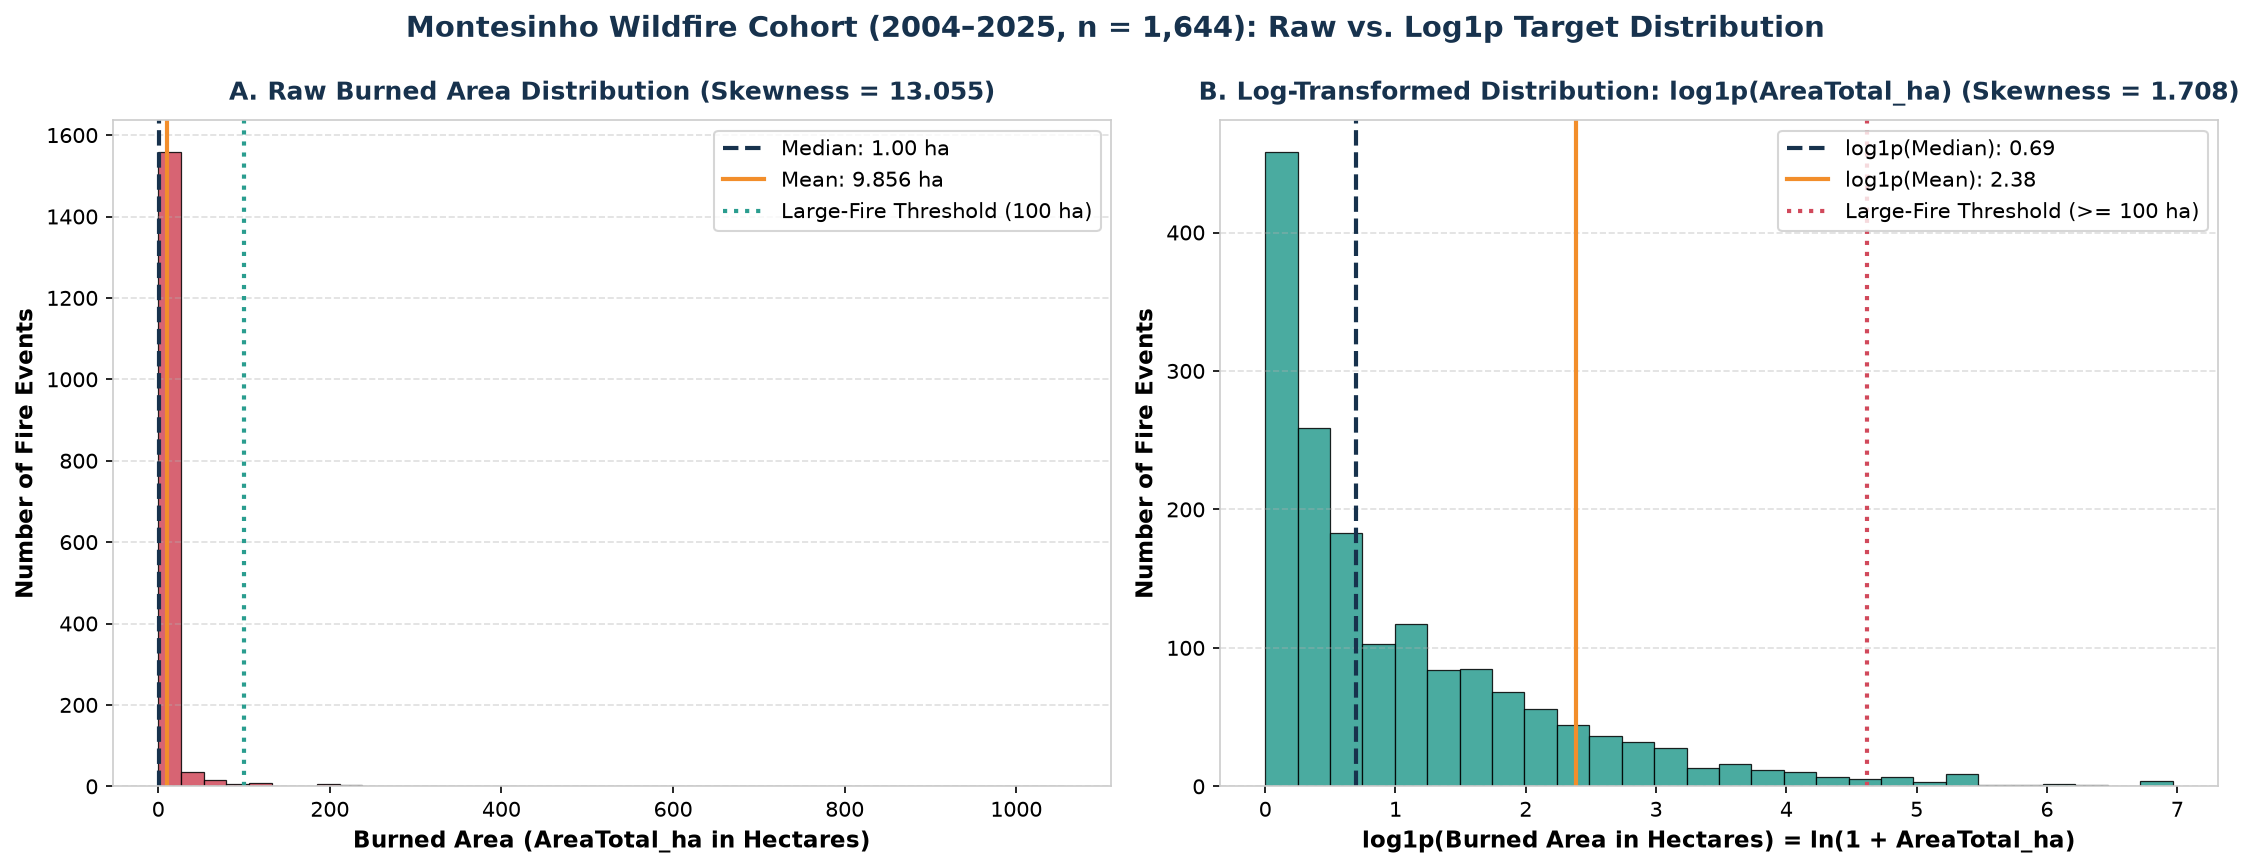

In [4]:
# Create a side-by-side figure comparing Raw AreaTotal_ha vs. log1p(AreaTotal_ha)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.8))

# --- Panel A: Raw Linear Burned Area (Hectares) ---
ax1.hist(area_ha, bins=40, color=RED, edgecolor="black", linewidth=0.6, alpha=0.85)
ax1.axvline(area_ha.median(), color=NAVY, linestyle="--", linewidth=2, label=f"Median: {area_ha.median():.2f} ha")
ax1.axvline(area_ha.mean(), color=ORANGE, linestyle="-", linewidth=2, label=f"Mean: {area_ha.mean():.3f} ha")
ax1.axvline(100.0, color=GREEN, linestyle=":", linewidth=2, label="Large-Fire Threshold (100 ha)")
ax1.set_title(f"A. Raw Burned Area Distribution (Skewness = {area_ha.skew():.3f})", fontsize=12, fontweight="bold", pad=10, color=NAVY)
ax1.set_xlabel("Burned Area (AreaTotal_ha in Hectares)", fontsize=11, fontweight="bold")
ax1.set_ylabel("Number of Fire Events", fontsize=11, fontweight="bold")
ax1.grid(axis="y", linestyle="--", alpha=0.4)
ax1.legend(loc="upper right", frameon=True, facecolor="white")

# --- Panel B: Log-Transformed Burned Area log1p(AreaTotal_ha) ---
log_area = df["_log1p_area"]
ax2.hist(log_area, bins=28, color=GREEN, edgecolor="black", linewidth=0.6, alpha=0.85)
ax2.axvline(np.log1p(area_ha.median()), color=NAVY, linestyle="--", linewidth=2, label=f"log1p(Median): {np.log1p(area_ha.median()):.2f}")
ax2.axvline(np.log1p(area_ha.mean()), color=ORANGE, linestyle="-", linewidth=2, label=f"log1p(Mean): {np.log1p(area_ha.mean()):.2f}")
ax2.axvline(np.log1p(100.0), color=RED, linestyle=":", linewidth=2, label="Large-Fire Threshold (>= 100 ha)")
ax2.set_title(f"B. Log-Transformed Distribution: log1p(AreaTotal_ha) (Skewness = {log_area.skew():.3f})", fontsize=12, fontweight="bold", pad=10, color=NAVY)
ax2.set_xlabel("log1p(Burned Area in Hectares) = ln(1 + AreaTotal_ha)", fontsize=11, fontweight="bold")
ax2.set_ylabel("Number of Fire Events", fontsize=11, fontweight="bold")
ax2.grid(axis="y", linestyle="--", alpha=0.4)
ax2.legend(loc="upper right", frameon=True, facecolor="white")

plt.suptitle("Montesinho Wildfire Cohort (2004–2025, n = 1,644): Raw vs. Log1p Target Distribution", fontsize=14, fontweight="bold", color=NAVY, y=0.99)
plt.tight_layout()

# Save to reports/figures/icnf_sgif/burned_area_log1p_distribution.png
log1p_fig_path = FIGURE_DIR / "burned_area_log1p_distribution.png"
plt.savefig(log1p_fig_path, dpi=300)
print(f"Saved side-by-side target distribution figure to: {log1p_fig_path.as_posix()}")
plt.show()


### Visual Findings: Raw vs. Log1p Target Scale

## Section 5: Burned-Area Size Group Distribution

Saved fire size group table to: reports/tables/icnf_sgif/eda_fire_size_groups.csv



,size_group,records,percentage
0,0 ha,19,1.156
1,>0 to <0.01,90,5.474
2,0.01 to <1,670,40.754
3,1 to <10,660,40.146
4,10 to <100,174,10.584
5,100 to <500,26,1.582
6,>=500,5,0.304


Saved size group bar chart to: reports/figures/icnf_sgif/fire_size_group_distribution.png


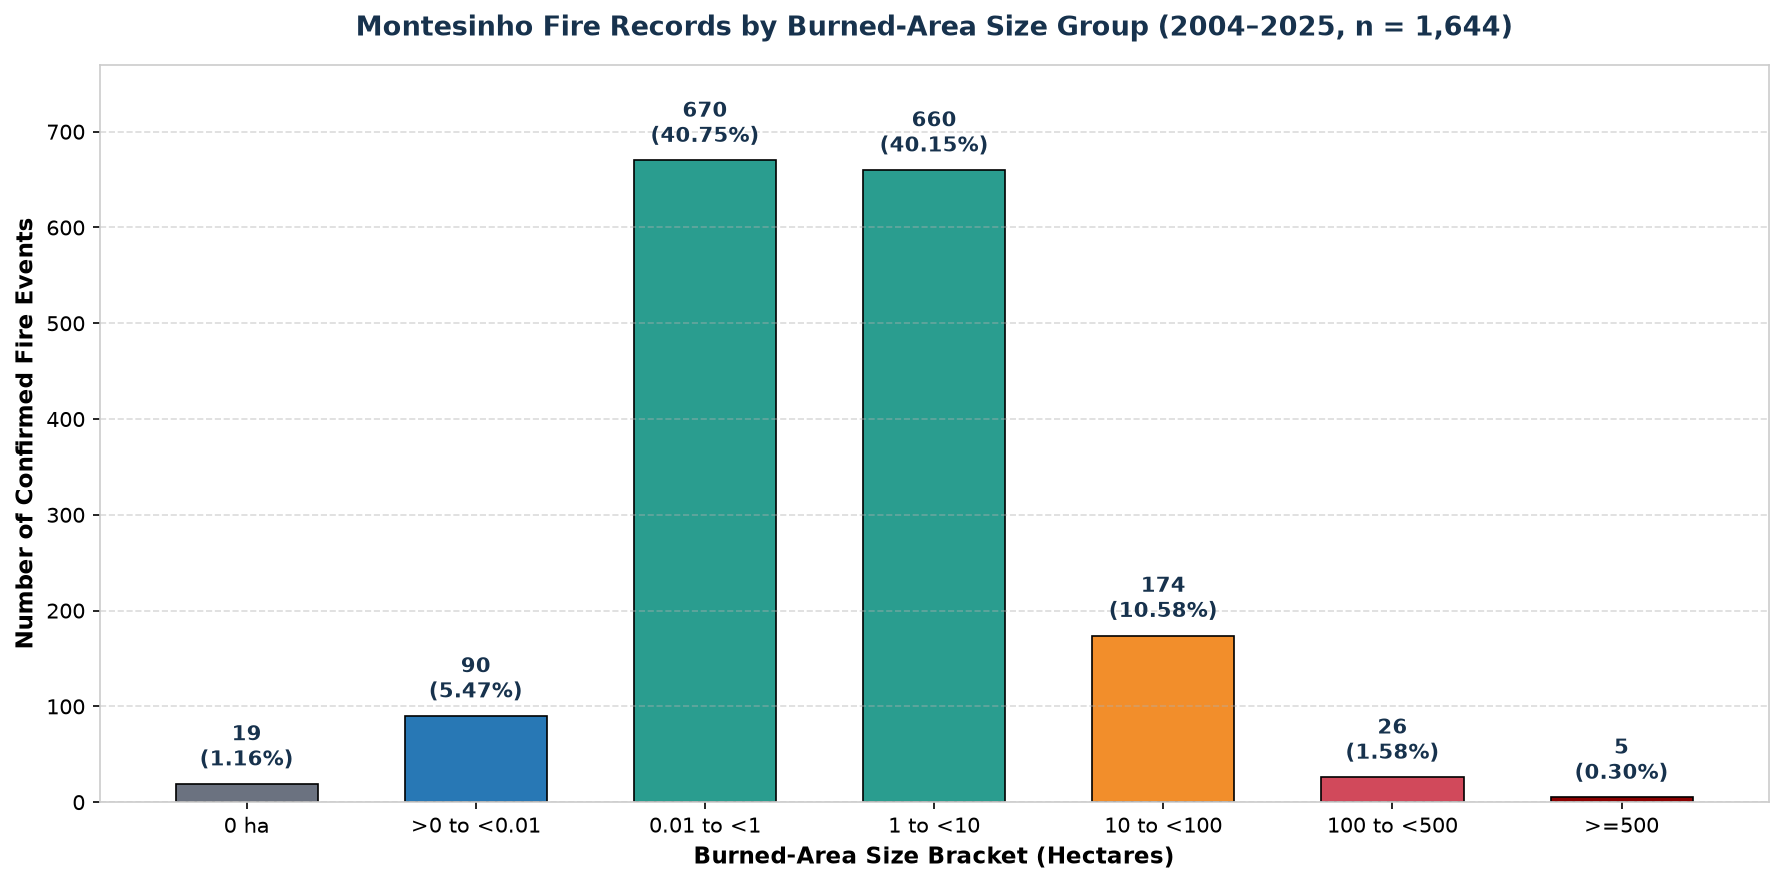

In [5]:
# Define the ordered operational fire-size brackets
size_labels = [
    "0 ha",
    ">0 to <0.01",
    "0.01 to <1",
    "1 to <10",
    "10 to <100",
    "100 to <500",
    ">=500",
]

# Assign each fire to its size group using clear beginner-friendly if/elif/else logic
assigned_groups = []
for value in area_ha:
    if value == 0.0:
        assigned_groups.append("0 ha")
    elif value < 0.01:
        assigned_groups.append(">0 to <0.01")
    elif value < 1.0:
        assigned_groups.append("0.01 to <1")
    elif value < 10.0:
        assigned_groups.append("1 to <10")
    elif value < 100.0:
        assigned_groups.append("10 to <100")
    elif value < 500.0:
        assigned_groups.append("100 to <500")
    else:
        assigned_groups.append(">=500")

df["_size_group"] = assigned_groups

# Count records and compute percentages in the exact bracket order
size_rows = []
for label in size_labels:
    count_in_group = int((df["_size_group"] == label).sum())
    pct_in_group = (count_in_group / len(df)) * 100.0
    size_rows.append({
        "size_group": label,
        "records": count_in_group,
        "percentage": pct_in_group,
    })

size_summary = pd.DataFrame(size_rows)

# Save table to reports/tables/icnf_sgif/eda_fire_size_groups.csv
size_group_table_path = TABLE_DIR / "eda_fire_size_groups.csv"
size_summary.to_csv(size_group_table_path, index=False)
print(f"Saved fire size group table to: {size_group_table_path.as_posix()}")
print()
display(size_summary)

# --- Plot Burned-Area Size Group Distribution ---
fig, ax = plt.subplots(figsize=(12, 6))
bar_colors = [GREY, BLUE, GREEN, GREEN, ORANGE, RED, "#8B0000"]

bars = ax.bar(
    size_summary["size_group"],
    size_summary["records"],
    color=bar_colors,
    width=0.62,
    edgecolor="black",
    linewidth=0.8,
)

ax.set_title("Montesinho Fire Records by Burned-Area Size Group (2004–2025, n = 1,644)", fontsize=13, fontweight="bold", color=NAVY, pad=14)
ax.set_xlabel("Burned-Area Size Bracket (Hectares)", fontsize=11, fontweight="bold")
ax.set_ylabel("Number of Confirmed Fire Events", fontsize=11, fontweight="bold")
ax.set_ylim(0, 770)
ax.grid(axis="y", linestyle="--", alpha=0.45)

# Annotate each bar with event count and percentage
for bar, (_, row) in zip(bars, size_summary.iterrows()):
    count_val = int(row["records"])
    pct_val = float(row["percentage"])
    ax.text(
        bar.get_x() + bar.get_width() / 2.0,
        bar.get_height() + 12,
        f"{count_val:,}\n({pct_val:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color=NAVY,
    )

plt.tight_layout()
size_fig_path = FIGURE_DIR / "fire_size_group_distribution.png"
plt.savefig(size_fig_path, dpi=300)
print(f"Saved size group bar chart to: {size_fig_path.as_posix()}")
plt.show()


## Section 6: Temporal & Seasonal Patterns (Annual, Monthly, and Hourly)


Saved annual summary table to: reports/tables/icnf_sgif/eda_year_summary.csv



,Ano,records,total_area_ha,median_area_ha,mean_area_ha,maximum_area_ha,fires_ge_100ha
0,2004,76,610.703,1.000,8.036,191.250,2
1,2005,97,1835.731,0.500,18.925,595.750,5
2,2006,54,90.047,0.500,1.668,18.300,0
3,2007,107,392.133,1.000,3.665,132.000,1
4,2008,72,558.624,1.000,7.759,97.500,0
5,2009,143,1495.361,1.000,10.457,829.560,2
6,2010,51,296.155,0.500,5.807,211.250,1
7,2011,154,750.324,0.975,4.872,209.090,1
8,2012,115,2587.553,1.500,22.500,829.750,5
9,2013,51,294.674,1.260,5.778,56.580,0


Saved annual fire counts figure to: reports/figures/icnf_sgif/montesinho_events_by_year_eda.png


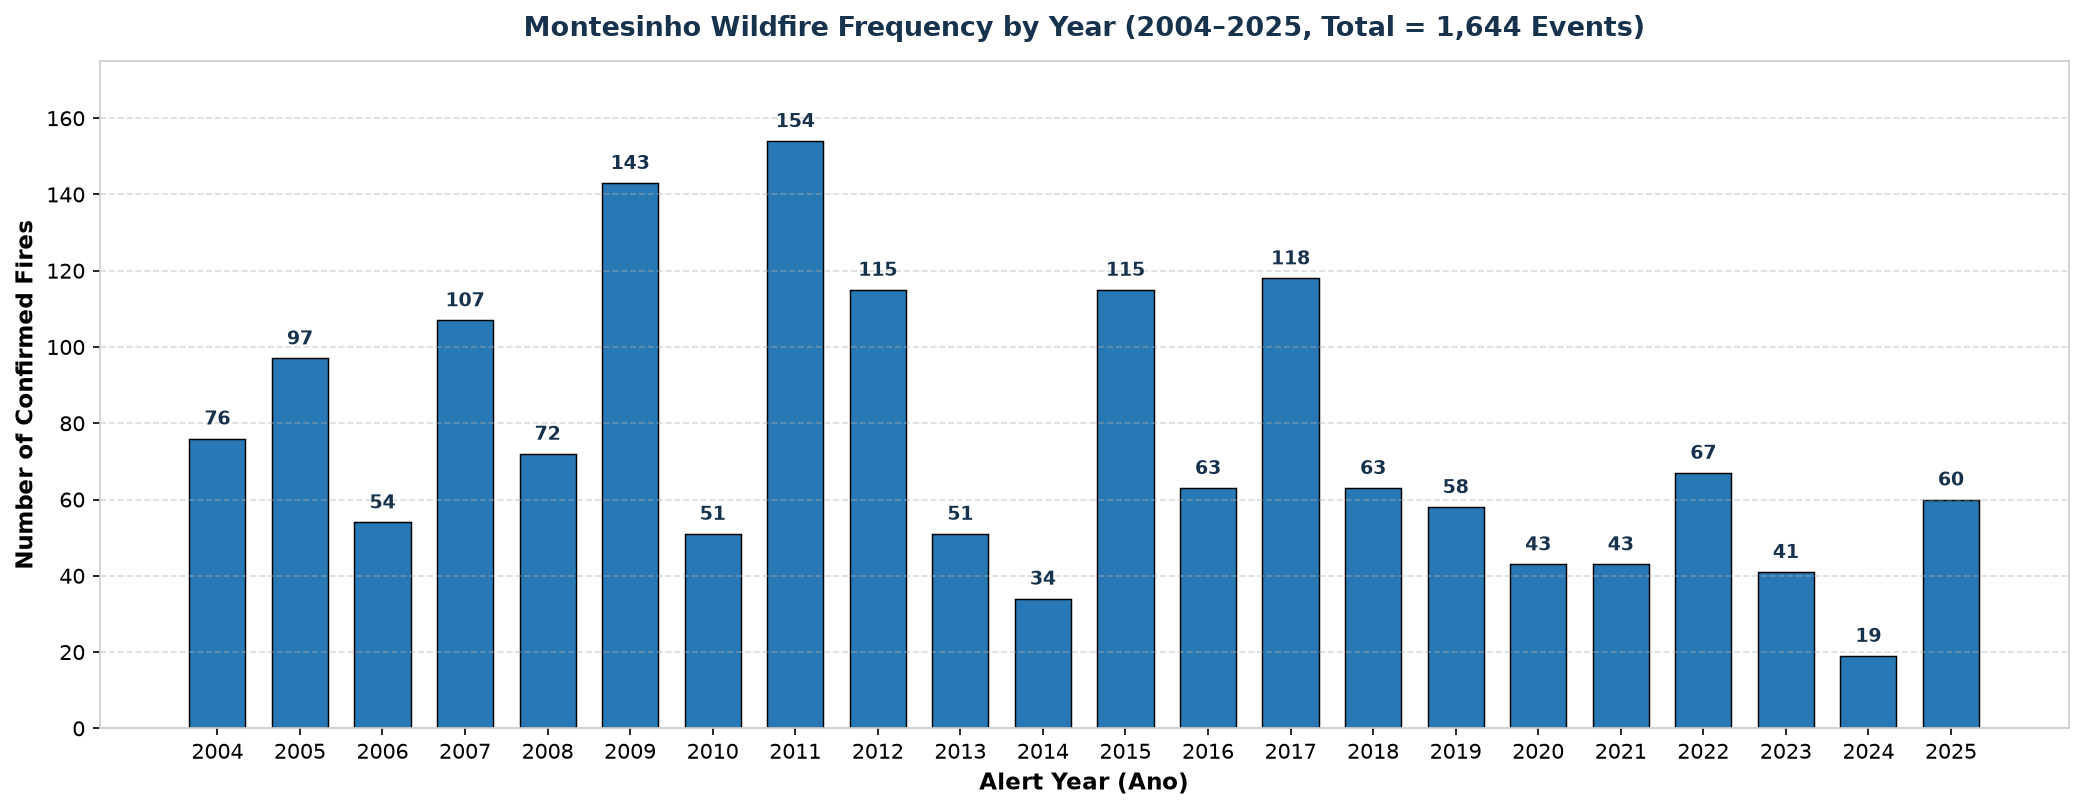

Saved annual burned area figure to: reports/figures/icnf_sgif/montesinho_total_area_by_year.png


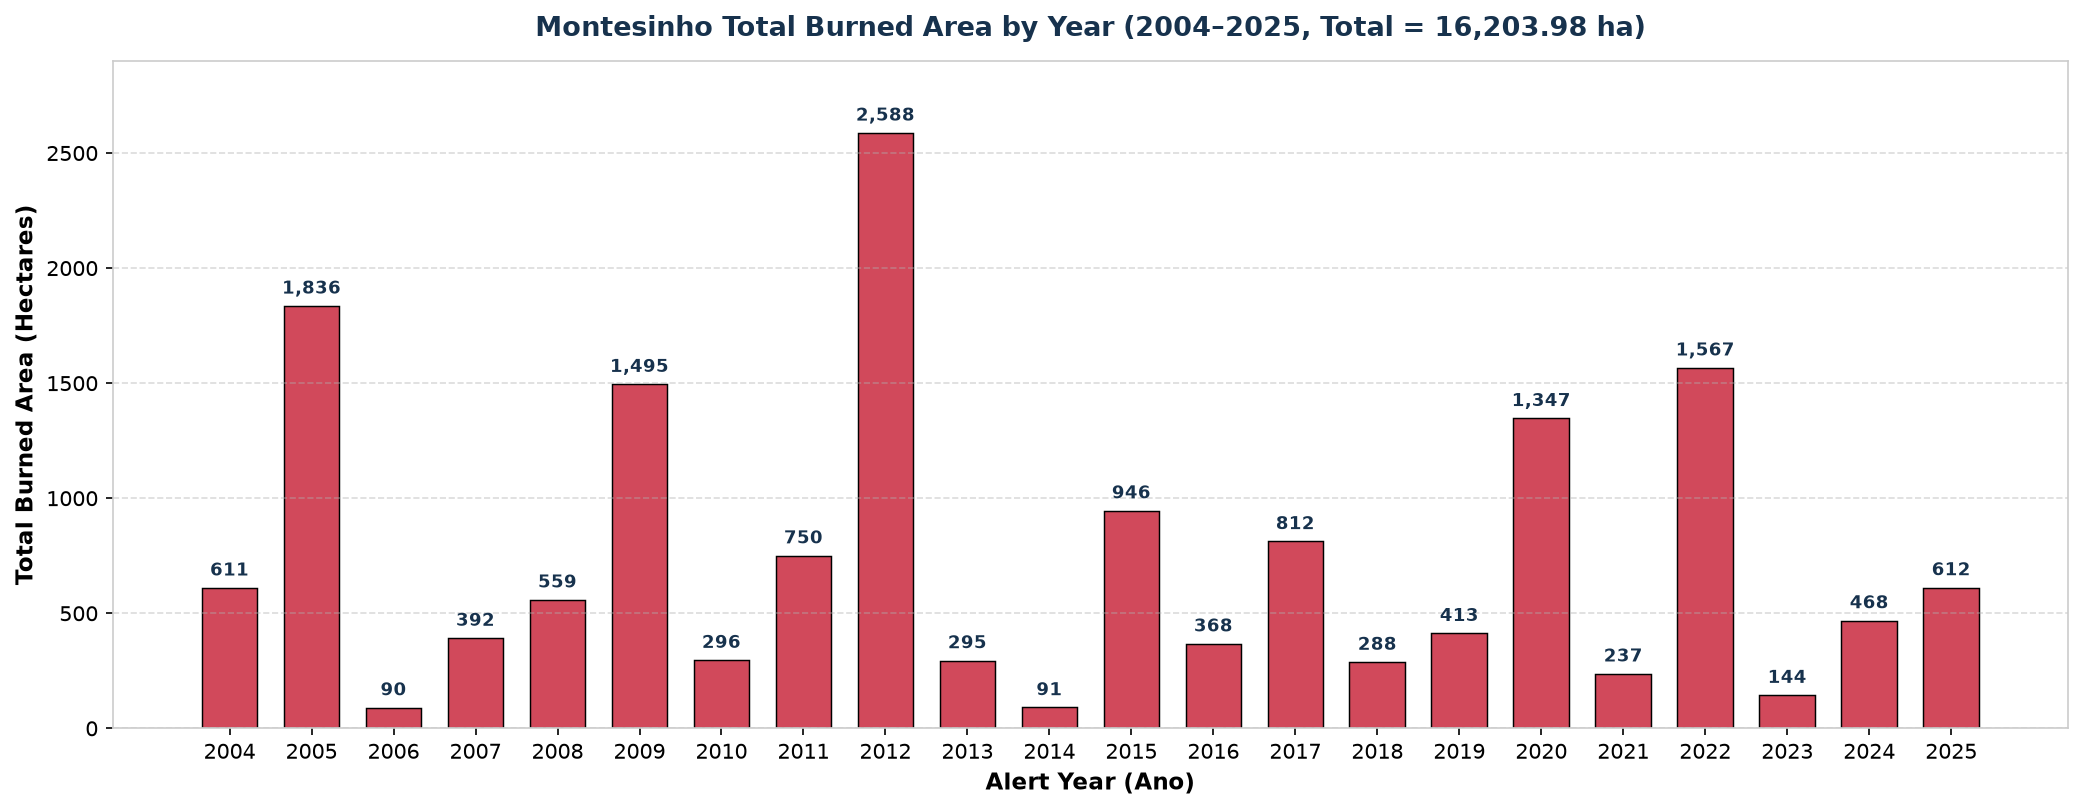

In [6]:
# Step 1: Compute Annual Summary Table (2004-2025) using a clear loop over sorted years
years_sorted = sorted(df["Ano"].unique())
year_rows = []

for year_val in years_sorted:
    year_subset = df[df["Ano"] == year_val]
    year_areas = year_subset["AreaTotal_ha"]
    year_rows.append({
        "Ano": int(year_val),
        "records": int(len(year_subset)),
        "total_area_ha": float(year_areas.sum()),
        "median_area_ha": float(year_areas.median()),
        "mean_area_ha": float(year_areas.mean()),
        "maximum_area_ha": float(year_areas.max()),
        "fires_ge_100ha": int((year_areas >= 100.0).sum()),
    })

year_summary = pd.DataFrame(year_rows)
year_table_path = TABLE_DIR / "eda_year_summary.csv"
year_summary.to_csv(year_table_path, index=False)
print(f"Saved annual summary table to: {year_table_path.as_posix()}")
print()
display(year_summary)

# --- Plot Annual Fire Counts (montesinho_events_by_year_eda.png) ---
fig, ax = plt.subplots(figsize=(14, 5.5))
year_labels = []
for y in year_summary["Ano"]:
    year_labels.append(str(y))

bars_count = ax.bar(year_labels, year_summary["records"], color=BLUE, edgecolor="black", linewidth=0.7, width=0.68)

ax.set_title("Montesinho Wildfire Frequency by Year (2004–2025, Total = 1,644 Events)", fontsize=13, fontweight="bold", color=NAVY, pad=12)
ax.set_xlabel("Alert Year (Ano)", fontsize=11, fontweight="bold")
ax.set_ylabel("Number of Confirmed Fires", fontsize=11, fontweight="bold")
ax.set_ylim(0, 175)
ax.grid(axis="y", linestyle="--", alpha=0.45)

for bar, count_val in zip(bars_count, year_summary["records"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2.0,
        bar.get_height() + 2.5,
        f"{int(count_val)}",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold",
        color=NAVY,
    )

plt.tight_layout()
year_count_fig_path = FIGURE_DIR / "montesinho_events_by_year_eda.png"
plt.savefig(year_count_fig_path, dpi=300)
print(f"Saved annual fire counts figure to: {year_count_fig_path.as_posix()}")
plt.show()

# --- Plot Annual Total Burned Area (montesinho_total_area_by_year.png) ---
fig, ax = plt.subplots(figsize=(14, 5.5))
bars_area = ax.bar(year_labels, year_summary["total_area_ha"], color=RED, edgecolor="black", linewidth=0.7, width=0.68)

ax.set_title("Montesinho Total Burned Area by Year (2004–2025, Total = 16,203.98 ha)", fontsize=13, fontweight="bold", color=NAVY, pad=12)
ax.set_xlabel("Alert Year (Ano)", fontsize=11, fontweight="bold")
ax.set_ylabel("Total Burned Area (Hectares)", fontsize=11, fontweight="bold")
ax.set_ylim(0, 2900)
ax.grid(axis="y", linestyle="--", alpha=0.45)

for bar, area_val in zip(bars_area, year_summary["total_area_ha"]):
    if area_val >= 10:
        label_str = f"{area_val:,.0f}"
    else:
        label_str = f"{area_val:.1f}"
    ax.text(
        bar.get_x() + bar.get_width() / 2.0,
        bar.get_height() + 35,
        label_str,
        ha="center",
        va="bottom",
        fontsize=8.5,
        fontweight="bold",
        color=NAVY,
    )

plt.tight_layout()
year_area_fig_path = FIGURE_DIR / "montesinho_total_area_by_year.png"
plt.savefig(year_area_fig_path, dpi=300)
print(f"Saved annual burned area figure to: {year_area_fig_path.as_posix()}")
plt.show()


Saved monthly summary table to: reports/tables/icnf_sgif/eda_month_summary.csv



,Mes,records,total_area_ha,median_area_ha,mean_area_ha,maximum_area_ha,month
0,1,47,1229.417,1.710,26.158,924.495,Jan
1,2,126,1583.777,2.087,12.570,829.750,Feb
2,3,274,4046.461,2.000,14.768,829.560,Mar
3,4,113,1198.731,2.440,10.608,194.000,Apr
4,5,35,62.046,0.500,1.773,17.080,May
5,6,40,89.617,0.210,2.240,44.000,Jun
6,7,131,1304.310,0.348,9.957,595.750,Jul
7,8,275,2445.358,0.500,8.892,445.180,Aug
8,9,297,2678.933,0.690,9.020,1057.500,Sep
9,10,228,1367.408,0.915,5.997,209.090,Oct


Saved monthly and hourly distribution figure to: reports/figures/icnf_sgif/montesinho_events_by_month.png


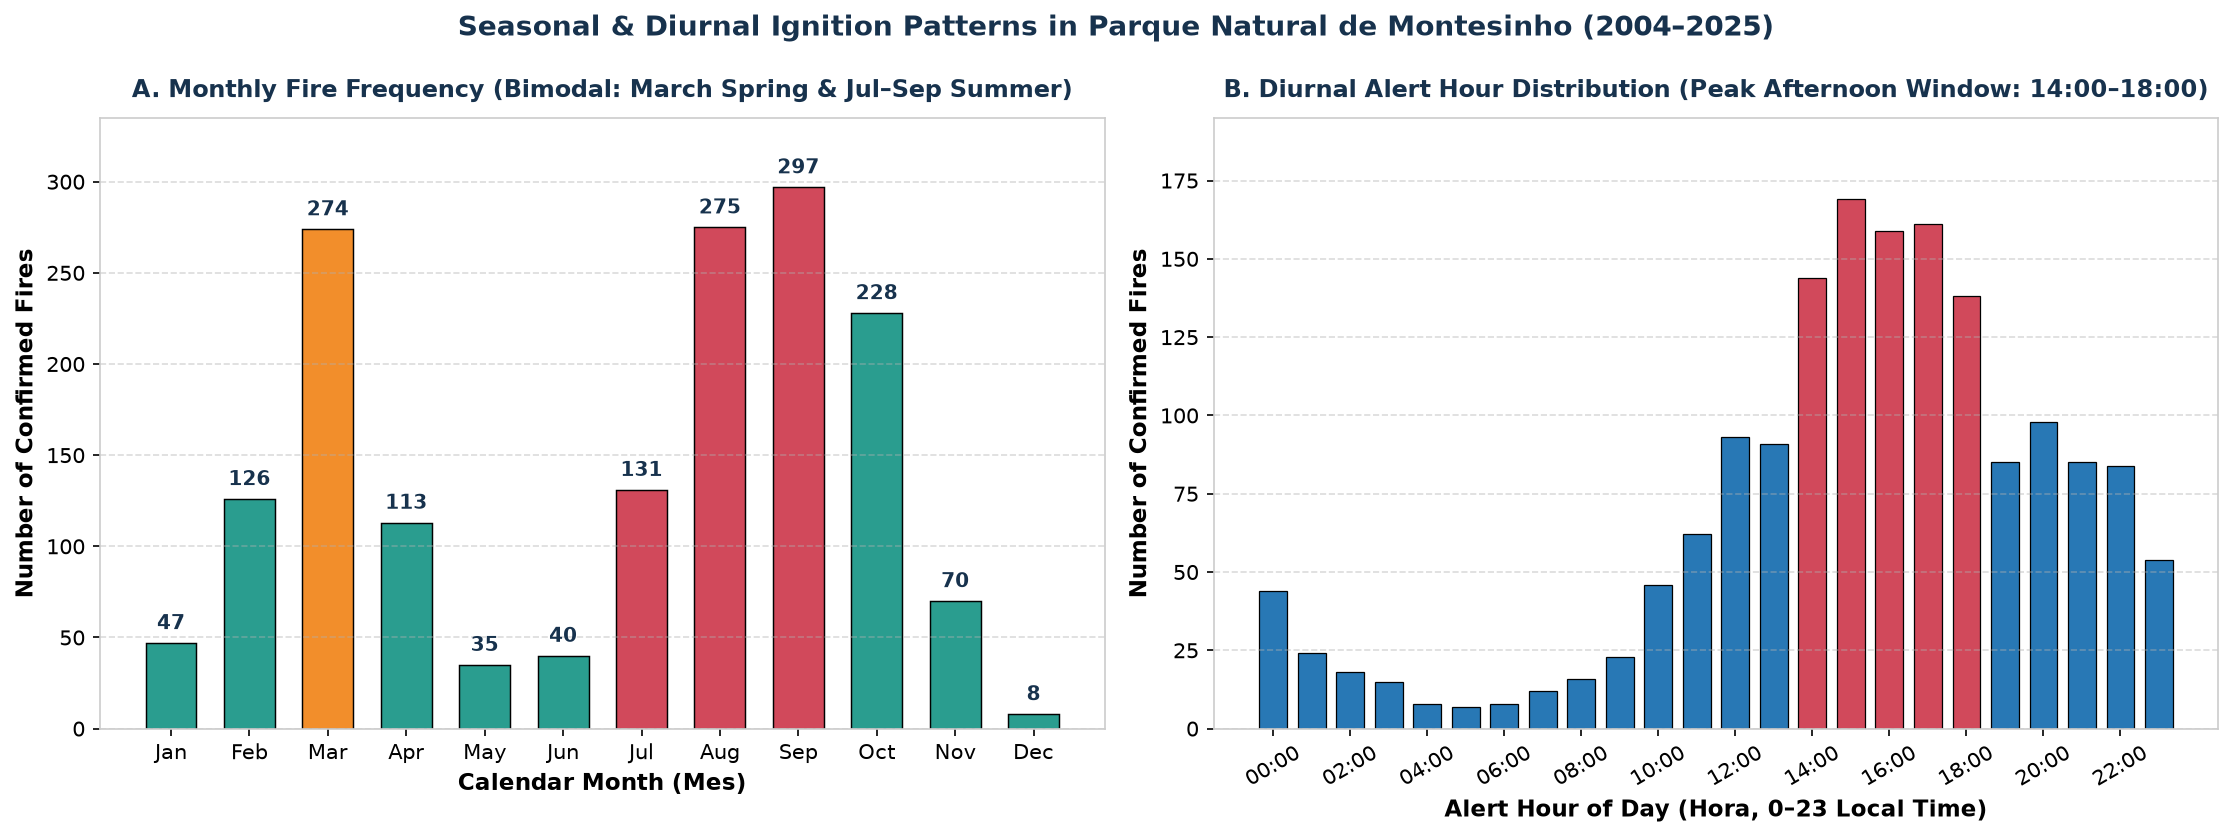

In [7]:
# Step 2: Compute Monthly Summary Table (Jan-Dec) and Hourly Alert Summary (00:00-23:00)
month_names = {
    1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "May", 6: "Jun",
    7: "Jul", 8: "Aug", 9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec",
}

month_rows = []
for month_num in range(1, 13):
    month_subset = df[df["Mes"] == month_num]
    month_areas = month_subset["AreaTotal_ha"]
    month_rows.append({
        "Mes": month_num,
        "records": int(len(month_subset)),
        "total_area_ha": float(month_areas.sum()),
        "median_area_ha": float(month_areas.median()),
        "mean_area_ha": float(month_areas.mean()),
        "maximum_area_ha": float(month_areas.max()),
        "month": month_names[month_num],
    })

month_summary = pd.DataFrame(month_rows)
month_table_path = TABLE_DIR / "eda_month_summary.csv"
month_summary.to_csv(month_table_path, index=False)
print(f"Saved monthly summary table to: {month_table_path.as_posix()}")
print()
display(month_summary)

# Compute hourly ignition counts (Hora 0 to 23)
hour_counts = []
for hour_val in range(24):
    hour_counts.append({
        "Hora": hour_val,
        "records": int((df["Hora"] == hour_val).sum()),
    })
hour_summary = pd.DataFrame(hour_counts)

# Assign bar colors for monthly and hourly charts using clear loops
month_colors = []
for m in month_summary["Mes"]:
    if m == 3:
        month_colors.append(ORANGE)
    elif m in [7, 8, 9]:
        month_colors.append(RED)
    else:
        month_colors.append(GREEN)

hour_colors = []
for h in hour_summary["Hora"]:
    if 14 <= h <= 18:
        hour_colors.append(RED)
    else:
        hour_colors.append(BLUE)

# --- Plot Monthly & Hourly Seasonal Patterns (montesinho_events_by_month.png) ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.6))

# Panel A: Monthly Fire Records
bars_m = ax1.bar(month_summary["month"], month_summary["records"], color=month_colors, edgecolor="black", linewidth=0.7, width=0.65)
ax1.set_title("A. Monthly Fire Frequency (Bimodal: March Spring & Jul–Sep Summer)", fontsize=11.5, fontweight="bold", color=NAVY, pad=10)
ax1.set_xlabel("Calendar Month (Mes)", fontsize=11, fontweight="bold")
ax1.set_ylabel("Number of Confirmed Fires", fontsize=11, fontweight="bold")
ax1.set_ylim(0, 335)
ax1.grid(axis="y", linestyle="--", alpha=0.45)

for bar, count_val in zip(bars_m, month_summary["records"]):
    ax1.text(
        bar.get_x() + bar.get_width() / 2.0,
        bar.get_height() + 5,
        f"{int(count_val)}",
        ha="center",
        va="bottom",
        fontsize=9.5,
        fontweight="bold",
        color=NAVY,
    )

# Panel B: Hourly Diurnal Alert Distribution
ax2.bar(hour_summary["Hora"], hour_summary["records"], color=hour_colors, edgecolor="black", linewidth=0.6, width=0.72)
ax2.set_title("B. Diurnal Alert Hour Distribution (Peak Afternoon Window: 14:00–18:00)", fontsize=11.5, fontweight="bold", color=NAVY, pad=10)
ax2.set_xlabel("Alert Hour of Day (Hora, 0–23 Local Time)", fontsize=11, fontweight="bold")
ax2.set_ylabel("Number of Confirmed Fires", fontsize=11, fontweight="bold")

even_hours = list(range(0, 24, 2))
even_hour_labels = []
for h in even_hours:
    even_hour_labels.append(f"{h:02d}:00")

ax2.set_xticks(even_hours)
ax2.set_xticklabels(even_hour_labels, rotation=30)
ax2.set_ylim(0, 195)
ax2.grid(axis="y", linestyle="--", alpha=0.45)

plt.suptitle("Seasonal & Diurnal Ignition Patterns in Parque Natural de Montesinho (2004–2025)", fontsize=13.5, fontweight="bold", color=NAVY, y=0.99)
plt.tight_layout()

month_fig_path = FIGURE_DIR / "montesinho_events_by_month.png"
plt.savefig(month_fig_path, dpi=300)
print(f"Saved monthly and hourly distribution figure to: {month_fig_path.as_posix()}")
plt.show()


## Section 7: Chronological Split Distribution Shift

In [8]:
# Part A: Save the 3-period historical comparison table (eda_period_comparison.csv)
period_definitions = [
    ("2004-2010", 2004, 2010),
    ("2011-2017", 2011, 2017),
    ("2018-2025", 2018, 2025),
]

period_rows = []
for label, start_yr, end_yr in period_definitions:
    sub = df[(df["Ano"] >= start_yr) & (df["Ano"] <= end_yr)]
    sub_area = sub["AreaTotal_ha"]
    period_rows.append({
        "_period": label,
        "records": int(len(sub)),
        "total_area_ha": float(sub_area.sum()),
        "median_area_ha": float(sub_area.median()),
        "mean_area_ha": float(sub_area.mean()),
        "maximum_area_ha": float(sub_area.max()),
        "median_FWI": float(sub["FWI"].median()),
        "fires_ge_100ha": int((sub_area >= 100.0).sum()),
    })

period_summary = pd.DataFrame(period_rows)
period_table_path = TABLE_DIR / "eda_period_comparison.csv"
period_summary.to_csv(period_table_path, index=False)

# Part B: Compute Chronological Modeling Split Summary
split_definitions = [
    ("Train (2004–2017)", 2004, 2017),
    ("Validation (2018–2021)", 2018, 2021),
    ("Protected Test (2022–2025)", 2022, 2025),
]

split_rows = []
for split_label, start_yr, end_yr in split_definitions:
    split_df = df[(df["Ano"] >= start_yr) & (df["Ano"] <= end_yr)]
    split_area = split_df["AreaTotal_ha"]
    missing_fwi_in_split = int(split_df[fwi_features].isna().any(axis=1).sum())

    split_rows.append({
        "Split": split_label,
        "Years": f"{start_yr}–{end_yr}",
        "Events": int(len(split_df)),
        "Share_Pct": (len(split_df) / len(df)) * 100.0,
        "Median_ha": round(float(split_area.median()), 2),
        "Mean_ha": round(float(split_area.mean()), 2),
        "Max_ha": round(float(split_area.max()), 2),
        "Fires_ge_100ha": int((split_area >= 100.0).sum()),
        "Missing_FWI_Rows": missing_fwi_in_split,
    })

split_summary_df = pd.DataFrame(split_rows)

print("Chronological Split Distribution Shift (2004–2025):")
display(split_summary_df)

print()
print(f"Broad Historical Period Comparison (saved to {period_table_path.as_posix()}):")
display(period_summary)


Chronological Split Distribution Shift (2004–2025):


,Split,Years,Events,Share_Pct,Median_ha,Mean_ha,Max_ha,Fires_ge_100ha,Missing_FWI_Rows
0,Train (2004–2017),2004–2017,1250,76.034,1.00,8.90,829.75,22,1
1,Validation (2018–2021),2018–2021,207,12.591,1.00,11.04,1057.50,4,1
2,Protected Test (2022–2025),2022–2025,187,11.375,1.08,14.93,924.50,5,1



Broad Historical Period Comparison (saved to reports/tables/icnf_sgif/eda_period_comparison.csv):


,_period,records,total_area_ha,median_area_ha,mean_area_ha,maximum_area_ha,median_FWI,fires_ge_100ha
0,2004-2010,600,5278.755,1.000,8.798,829.56,17.159,11
1,2011-2017,650,5848.978,1.185,8.998,829.75,20.785,11
2,2018-2025,394,5076.245,1.015,12.884,1057.50,16.423,9


## Section 8: Alert-Time Fire Weather Index (FWI) Relationships & Correlations

Saved FWI summary table to     : reports/tables/icnf_sgif/eda_fwi_summary.csv
Saved FWI correlation table to : reports/tables/icnf_sgif/eda_fwi_target_correlations.csv

Alert-Time FWI Descriptive Summary:


,feature,missing,minimum,median,mean,maximum
0,FFMC,3,3.510e+01,89.369,88.162,97.974
1,DMC,3,4.383e-01,44.435,64.279,348.005
2,DC,3,7.548e-01,418.792,390.396,1087.282
3,ISI,3,2.446e-02,6.342,6.740,21.990
4,BUI,3,2.688e-01,63.665,85.682,386.279
5,FWI,3,5.562e-02,18.202,19.572,63.546
6,DSR,3,1.636e-04,4.624,6.845,42.270



Pearson and Spearman Correlations with log1p(AreaTotal_ha):


,feature,complete_records,pearson_with_log1p_area,spearman_with_log1p_area
0,FFMC,1641,0.044,-0.044
1,DMC,1641,-0.100,-0.164
2,DC,1641,-0.161,-0.200
3,ISI,1641,0.055,-0.009
4,BUI,1641,-0.114,-0.181
5,FWI,1641,-0.055,-0.116
6,DSR,1641,-0.044,-0.116


Saved FWI correlation chart to: reports/figures/icnf_sgif/fwi_spearman_correlations.png


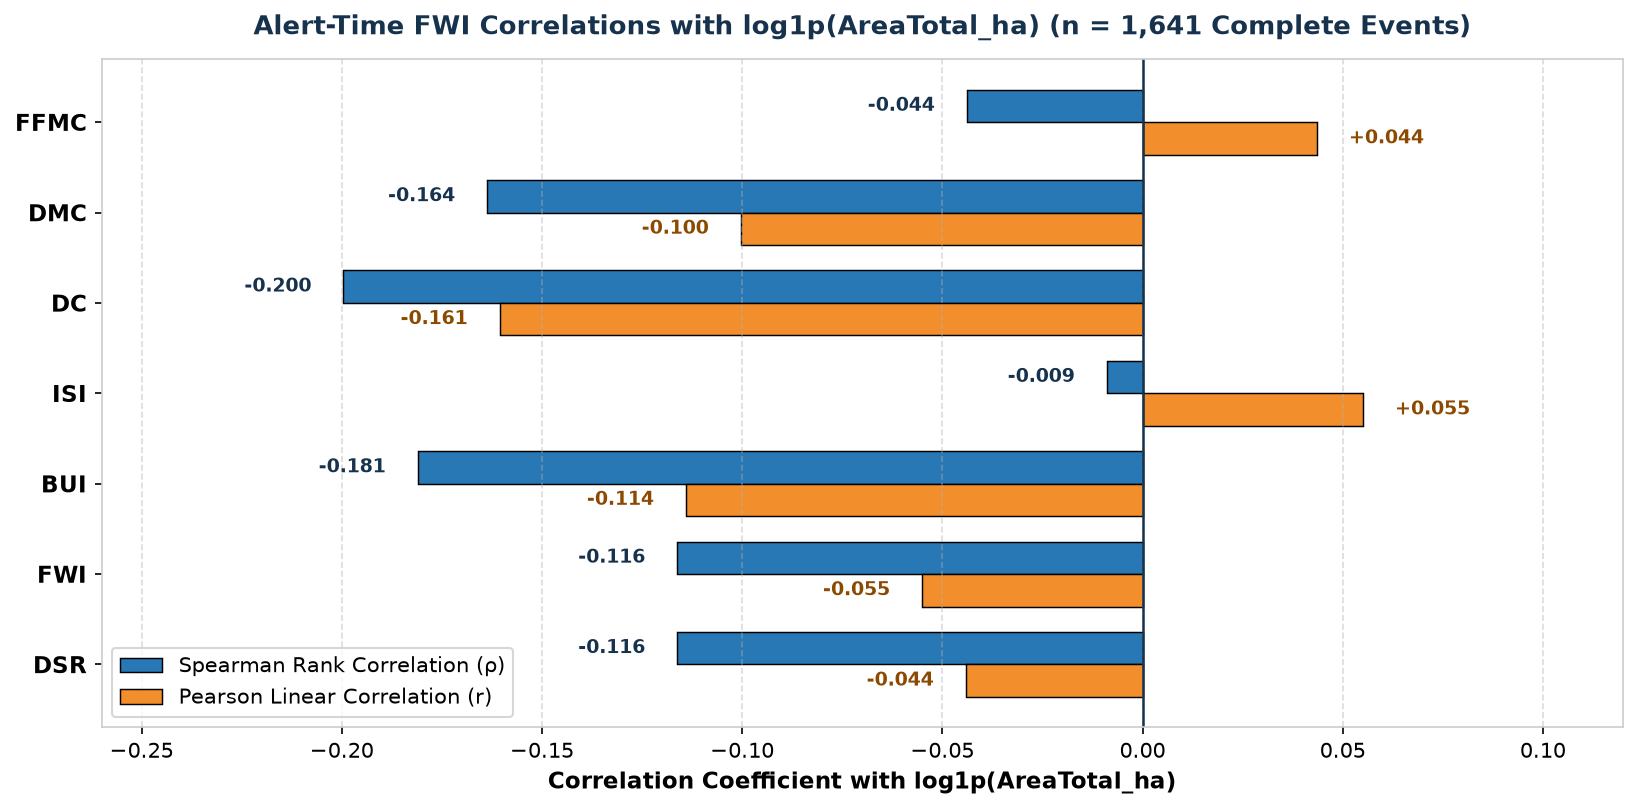

In [9]:
# Compute descriptive statistics and target correlations for each FWI component
correlation_rows = []
fwi_summary_rows = []

for feature_name in fwi_features:
    feature_series = pd.to_numeric(df[feature_name], errors="coerce")
    valid_mask = feature_series.notna() & df["_log1p_area"].notna()

    valid_feature = feature_series[valid_mask]
    valid_target = df.loc[valid_mask, "_log1p_area"]

    # Pearson linear correlation and Spearman rank correlation
    pearson_r = float(valid_feature.corr(valid_target))
    spearman_r = float(valid_feature.rank().corr(valid_target.rank()))

    correlation_rows.append({
        "feature": feature_name,
        "complete_records": int(valid_mask.sum()),
        "pearson_with_log1p_area": pearson_r,
        "spearman_with_log1p_area": spearman_r,
    })

    fwi_summary_rows.append({
        "feature": feature_name,
        "missing": int(feature_series.isna().sum()),
        "minimum": float(feature_series.min()),
        "median": float(feature_series.median()),
        "mean": float(feature_series.mean()),
        "maximum": float(feature_series.max()),
    })

fwi_correlations = pd.DataFrame(correlation_rows)
fwi_summary = pd.DataFrame(fwi_summary_rows)

# Save both FWI report tables
fwi_corr_path = TABLE_DIR / "eda_fwi_target_correlations.csv"
fwi_sum_path = TABLE_DIR / "eda_fwi_summary.csv"
fwi_correlations.to_csv(fwi_corr_path, index=False)
fwi_summary.to_csv(fwi_sum_path, index=False)

print(f"Saved FWI summary table to     : {fwi_sum_path.as_posix()}")
print(f"Saved FWI correlation table to : {fwi_corr_path.as_posix()}")
print()
print("Alert-Time FWI Descriptive Summary:")
display(fwi_summary)

print()
print("Pearson and Spearman Correlations with log1p(AreaTotal_ha):")
display(fwi_correlations)

# --- Plot FWI Correlations with log1p(AreaTotal_ha) (fwi_spearman_correlations.png) ---
fig, ax = plt.subplots(figsize=(11, 5.5))
y_positions = np.arange(len(fwi_correlations))
bar_height = 0.36

bars_spearman = ax.barh(
    y_positions - bar_height / 2,
    fwi_correlations["spearman_with_log1p_area"],
    height=bar_height,
    color=BLUE,
    edgecolor="black",
    linewidth=0.7,
    label="Spearman Rank Correlation (ρ)",
)
bars_pearson = ax.barh(
    y_positions + bar_height / 2,
    fwi_correlations["pearson_with_log1p_area"],
    height=bar_height,
    color=ORANGE,
    edgecolor="black",
    linewidth=0.7,
    label="Pearson Linear Correlation (r)",
)

ax.axvline(0.0, color=NAVY, linewidth=1.2, linestyle="-")
ax.set_yticks(y_positions)
ax.set_yticklabels(fwi_correlations["feature"], fontsize=11, fontweight="bold")
ax.invert_yaxis()
ax.set_xlim(-0.26, 0.12)
ax.set_title("Alert-Time FWI Correlations with log1p(AreaTotal_ha) (n = 1,641 Complete Events)", fontsize=12.5, fontweight="bold", color=NAVY, pad=12)
ax.set_xlabel("Correlation Coefficient with log1p(AreaTotal_ha)", fontsize=11, fontweight="bold")
ax.grid(axis="x", linestyle="--", alpha=0.45)
ax.legend(loc="lower left", frameon=True, facecolor="white")

for bar in bars_spearman:
    val = bar.get_width()
    if val < 0:
        offset = -0.008
        align = "right"
    else:
        offset = 0.008
        align = "left"
    ax.text(val + offset, bar.get_y() + bar.get_height() / 2, f"{val:+.3f}", va="center", ha=align, fontsize=9, fontweight="bold", color=NAVY)

for bar in bars_pearson:
    val = bar.get_width()
    if val < 0:
        offset = -0.008
        align = "right"
    else:
        offset = 0.008
        align = "left"
    ax.text(val + offset, bar.get_y() + bar.get_height() / 2, f"{val:+.3f}", va="center", ha=align, fontsize=9, fontweight="bold", color="#8C4A00")

plt.tight_layout()
fwi_fig_path = FIGURE_DIR / "fwi_spearman_correlations.png"
plt.savefig(fwi_fig_path, dpi=300)
print(f"Saved FWI correlation chart to: {fwi_fig_path.as_posix()}")
plt.show()


## Section 9: Spatial & Municipal Analysis (Bragança vs. Vinhais) and Extreme Fires

Municipal Wildfire Comparison (Bragança vs. Vinhais):


,Municipality,Events,Share_Events_Pct,Total_Area_ha,Share_Area_Pct,Median_ha,Mean_ha,Max_ha,Fires_ge_100ha
0,Bragança,831,50.547,8282.231,51.112,0.900,9.967,924.495,18
1,Vinhais,807,49.088,7921.226,48.884,1.113,9.816,1057.500,13
2,Other Text Labels (Geometry Inside PNM),6,0.365,0.521,0.003,0.011,0.087,0.400,0



Saved parish location summary table to: reports/tables/icnf_sgif/eda_location_summary.csv (Top 10 Parishes):


,Concelho,Freguesia,records,total_area_ha,median_area_ha,maximum_area_ha
48,Vinhais,Moimenta,142,655.570,1.000,45.830
15,Bragança,França,128,2420.213,1.010,924.495
52,Vinhais,Quirás,101,1546.910,1.950,356.000
1,Bragança,Aveleda,81,906.811,1.000,248.544
22,Bragança,Parâmio,80,552.056,1.096,100.350
68,Vinhais,Vilar Seco de Lomba,73,322.840,1.000,69.000
36,Bragança,São Julião de Palácios,66,289.106,0.500,209.090
62,Vinhais,Tuizelo,64,1067.534,1.260,829.560
2,Bragança,Babe,62,347.645,1.116,115.630
12,Bragança,Deilão,57,909.722,0.500,595.750



Saved Top 20 Extreme Fires table to: reports/tables/icnf_sgif/eda_extreme_fires_top20.csv (Top 10 Largest Events):


,Codigo_SGIF,Ano,Mes,DataHoraAlerta,AreaTotal_ha,Concelho,Freguesia,Local,FWI
1396,TM220323,2020,9,2020-09-04 22:27:00,1057.500,Vinhais,Pinheiro Novo,Pinheiro Velho (Raposeira),32.527
1461,2022_04_0002704,2022,1,2022-01-28 08:00:00,924.495,Bragança,França,Lama Grande (Fonte Ferrugenta),11.903
781,TM212271,2012,2,2012-02-27 14:39:00,829.750,Bragança,França,LAMA GRANDE-PNM (Lameiros da Serra),7.518
446,TM209211,2009,3,2009-03-22 09:30:00,829.560,Vinhais,Tuizelo,Lugar da rapada- Quadra,13.785
119,TM205676,2005,7,2005-07-24 13:40:00,595.750,Bragança,Deilão,Albagueiras,36.048
797,TM212390,2012,3,2012-03-11 09:29:00,472.000,Vinhais,Mofreita,MOFREITA-PNM (Lombo do Seixo),14.495
1573,20240986285,2024,8,2024-08-10 18:54:00,445.180,Bragança,Carragosa,Soutelo 2 (Cerro),37.620
130,TM205842,2005,8,2005-08-18 14:22:00,356.000,Vinhais,Quirás,Edroso,27.967
1607,20250974143,2025,7,2025-07-25 12:07:00,248.544,Bragança,Aveleda,"Aveleda, Bragança, Portugal (AVELEDA)",37.204
129,TM205845,2005,8,2005-08-18 01:26:00,236.000,Vinhais,Quirás,Edroso,26.968


Saved spatial and municipal figure to: reports/figures/icnf_sgif/montesinho_burned_area_spatial_distribution.png


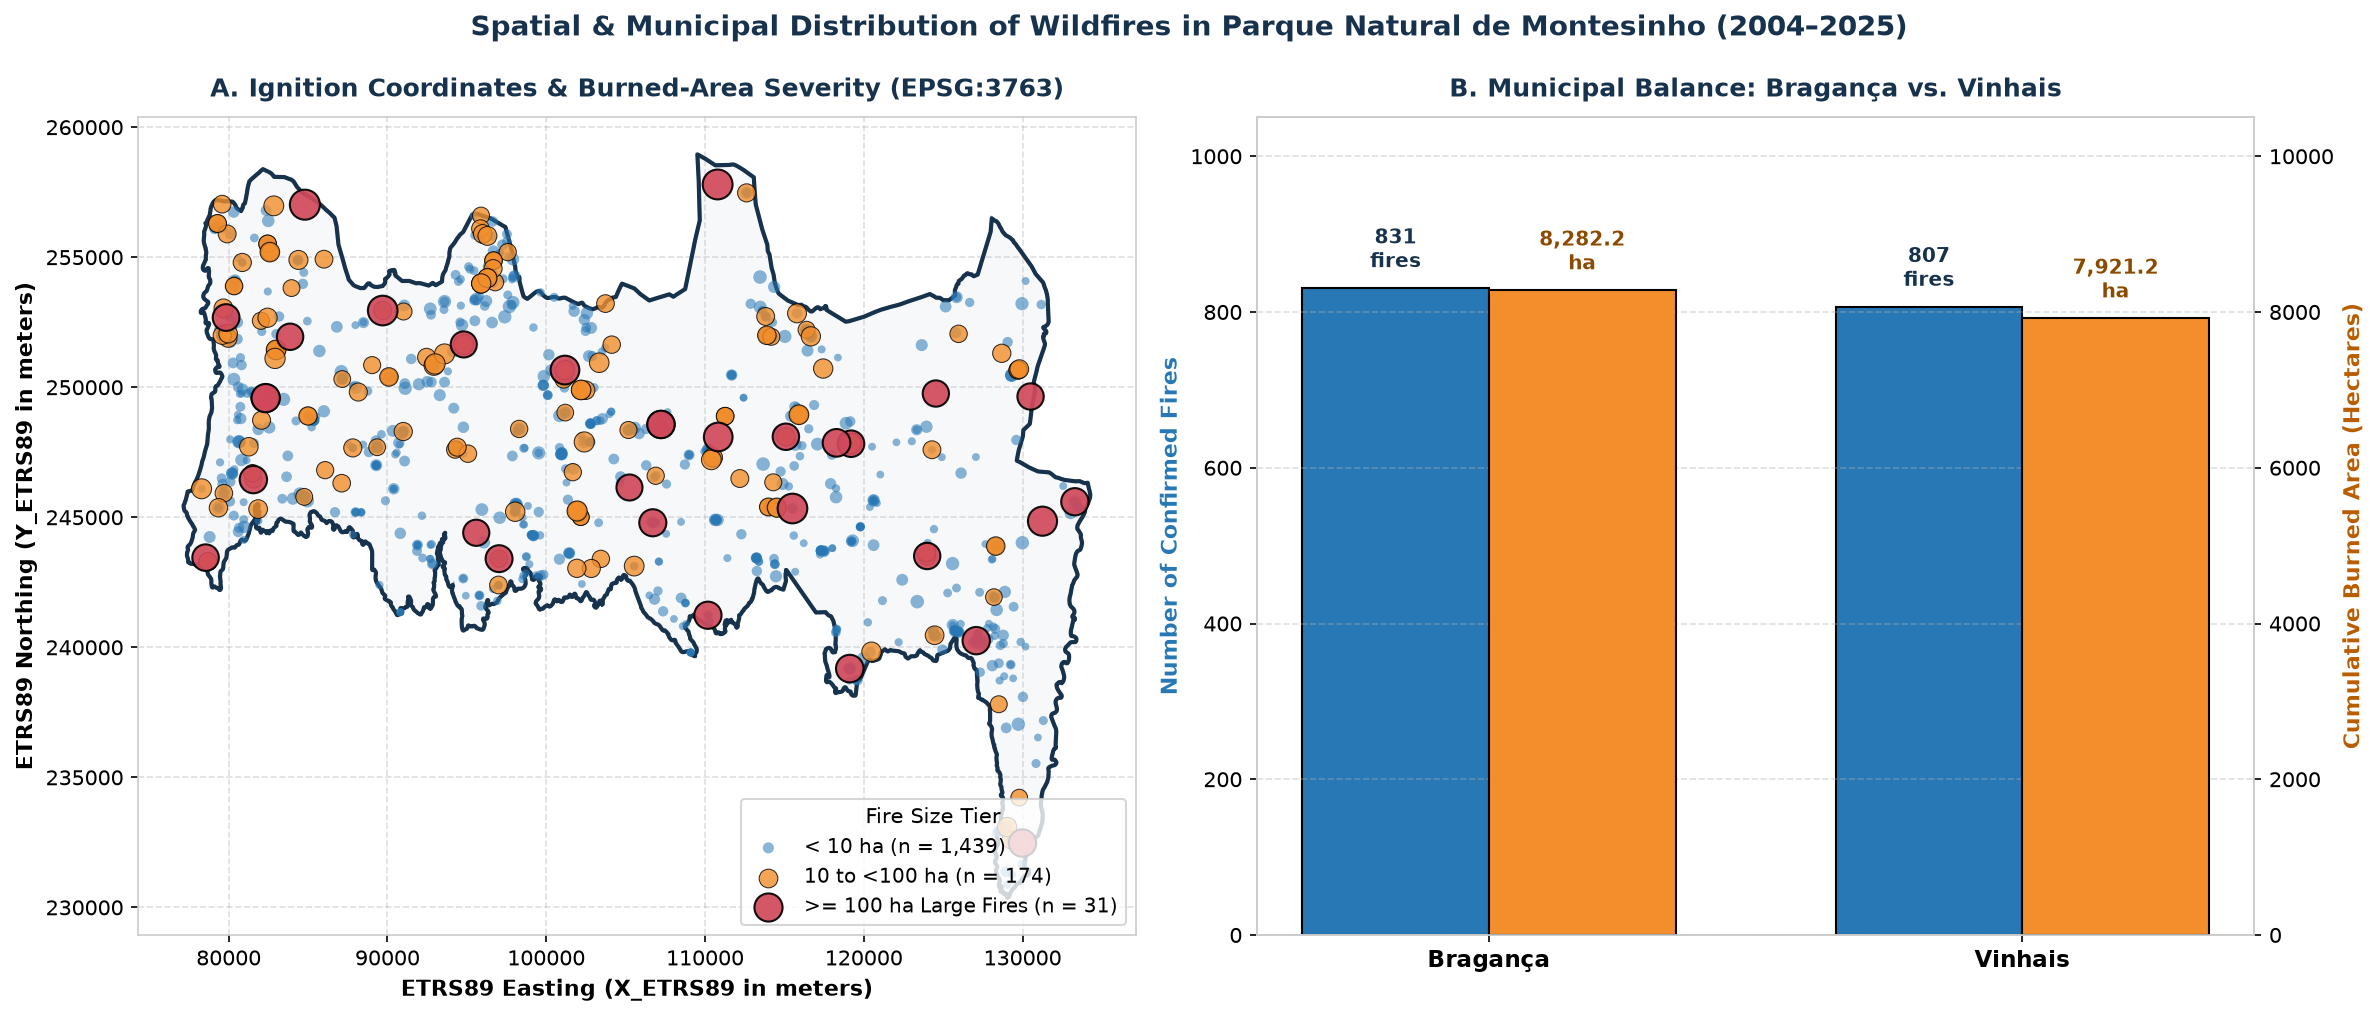

In [10]:
# 1. Municipal (Concelho) Comparison: Bragança vs. Vinhais
municipal_rows = []
for muni_name in ["Bragança", "Vinhais"]:
    muni_df = df[df["Concelho"] == muni_name]
    muni_area = muni_df["AreaTotal_ha"]
    municipal_rows.append({
        "Municipality": muni_name,
        "Events": int(len(muni_df)),
        "Share_Events_Pct": (len(muni_df) / len(df)) * 100.0,
        "Total_Area_ha": float(muni_area.sum()),
        "Share_Area_Pct": (muni_area.sum() / df["AreaTotal_ha"].sum()) * 100.0,
        "Median_ha": float(muni_area.median()),
        "Mean_ha": float(muni_area.mean()),
        "Max_ha": float(muni_area.max()),
        "Fires_ge_100ha": int((muni_area >= 100.0).sum()),
    })

other_muni_df = df[~df["Concelho"].isin(["Bragança", "Vinhais"])]
other_area = other_muni_df["AreaTotal_ha"]
municipal_rows.append({
    "Municipality": "Other Text Labels (Geometry Inside PNM)",
    "Events": int(len(other_muni_df)),
    "Share_Events_Pct": (len(other_muni_df) / len(df)) * 100.0,
    "Total_Area_ha": float(other_area.sum()),
    "Share_Area_Pct": (other_area.sum() / df["AreaTotal_ha"].sum()) * 100.0,
    "Median_ha": float(other_area.median()),
    "Mean_ha": float(other_area.mean()),
    "Max_ha": float(other_area.max()),
    "Fires_ge_100ha": int((other_area >= 100.0).sum()),
})

municipal_summary = pd.DataFrame(municipal_rows)
print("Municipal Wildfire Comparison (Bragança vs. Vinhais):")
display(municipal_summary)

# 2. Parish-Level (Concelho + Freguesia) Location Summary (eda_location_summary.csv)
location_summary = (
    df.groupby(["Concelho", "Freguesia"], dropna=False, as_index=False)
    .agg(
        records=("Codigo_SGIF", "size"),
        total_area_ha=("AreaTotal_ha", "sum"),
        median_area_ha=("AreaTotal_ha", "median"),
        maximum_area_ha=("AreaTotal_ha", "max"),
    )
    .sort_values(["records", "total_area_ha"], ascending=False)
)
location_table_path = TABLE_DIR / "eda_location_summary.csv"
location_summary.to_csv(location_table_path, index=False)
print()
print(f"Saved parish location summary table to: {location_table_path.as_posix()} (Top 10 Parishes):")
display(location_summary.head(10))

# 3. Top 20 Extreme Fires Audit Table (eda_extreme_fires_top20.csv)
extreme_columns = [
    "Codigo_SGIF", "Ano", "Mes", "DataHoraAlerta", "AreaTotal_ha",
    "Distrito", "Concelho", "Freguesia", "Local", "GrupoCausa", "TipoCausa",
    "FFMC", "DMC", "DC", "ISI", "BUI", "FWI", "DSR", "X_ETRS89", "Y_ETRS89",
]
extreme_fires = df.nlargest(20, "AreaTotal_ha")[extreme_columns].copy()
extreme_table_path = TABLE_DIR / "eda_extreme_fires_top20.csv"
extreme_fires.to_csv(extreme_table_path, index=False)
print()
print(f"Saved Top 20 Extreme Fires table to: {extreme_table_path.as_posix()} (Top 10 Largest Events):")
display(extreme_fires[["Codigo_SGIF", "Ano", "Mes", "DataHoraAlerta", "AreaTotal_ha", "Concelho", "Freguesia", "Local", "FWI"]].head(10))

# 4. Plot Spatial Map + Municipal Comparison (montesinho_burned_area_spatial_distribution.png)
with open(BOUNDARY_PATH, "r", encoding="utf-8-sig") as f_geo:
    boundary_json = json.load(f_geo)
boundary_geometry = boundary_json["features"][0]["geometry"]

boundary_rings = []
if boundary_geometry["type"] == "Polygon":
    for ring in boundary_geometry["coordinates"]:
        boundary_rings.append(ring)
else:
    for poly in boundary_geometry["coordinates"]:
        for ring in poly:
            boundary_rings.append(ring)

fig, (ax_map, ax_muni) = plt.subplots(1, 2, figsize=(16, 6.8))

# --- Panel A: Spatial Map of Burned Area Severity Inside Official Boundary ---
for ring in boundary_rings:
    ring_x = [pt[0] for pt in ring]
    ring_y = [pt[1] for pt in ring]
    ax_map.plot(ring_x, ring_y, color=NAVY, linewidth=2.0, zorder=2)
    poly_patch = MplPolygon(ring, closed=True, facecolor="#EEF3F7", edgecolor=NAVY, linewidth=1.5, alpha=0.5, zorder=1)
    ax_map.add_patch(poly_patch)

# Sort events from smallest to largest so large fires are drawn on top
ordered_df = df.sort_values("AreaTotal_ha")
small_mask = ordered_df["AreaTotal_ha"] < 10.0
medium_mask = (ordered_df["AreaTotal_ha"] >= 10.0) & (ordered_df["AreaTotal_ha"] < 100.0)
large_mask = ordered_df["AreaTotal_ha"] >= 100.0

ax_map.scatter(
    ordered_df.loc[small_mask, "X_ETRS89"],
    ordered_df.loc[small_mask, "Y_ETRS89"],
    s=14 + ordered_df.loc[small_mask, "_log1p_area"] * 12,
    c=BLUE,
    alpha=0.55,
    edgecolors="none",
    label=f"< 10 ha (n = {int(small_mask.sum()):,})",
    zorder=3,
)
ax_map.scatter(
    ordered_df.loc[medium_mask, "X_ETRS89"],
    ordered_df.loc[medium_mask, "Y_ETRS89"],
    s=28 + ordered_df.loc[medium_mask, "_log1p_area"] * 15,
    c=ORANGE,
    alpha=0.80,
    edgecolors="black",
    linewidth=0.5,
    label=f"10 to <100 ha (n = {int(medium_mask.sum()):,})",
    zorder=4,
)
ax_map.scatter(
    ordered_df.loc[large_mask, "X_ETRS89"],
    ordered_df.loc[large_mask, "Y_ETRS89"],
    s=55 + ordered_df.loc[large_mask, "_log1p_area"] * 22,
    c=RED,
    alpha=0.92,
    edgecolors="black",
    linewidth=1.0,
    label=f">= 100 ha Large Fires (n = {int(large_mask.sum()):,})",
    zorder=5,
)

ax_map.set_title("A. Ignition Coordinates & Burned-Area Severity (EPSG:3763)", fontsize=12, fontweight="bold", color=NAVY, pad=10)
ax_map.set_xlabel("ETRS89 Easting (X_ETRS89 in meters)", fontsize=10.5, fontweight="bold")
ax_map.set_ylabel("ETRS89 Northing (Y_ETRS89 in meters)", fontsize=10.5, fontweight="bold")
ax_map.ticklabel_format(style="plain", useOffset=False)
ax_map.grid(True, linestyle="--", alpha=0.4)
ax_map.legend(loc="lower right", frameon=True, facecolor="white", title="Fire Size Tier", fontsize=9.5)

# --- Panel B: Municipal Comparison (Bragança vs. Vinhais) ---
main_muni = municipal_summary.iloc[:2]
x_idx = np.arange(len(main_muni))
width_m = 0.35

bars_ev = ax_muni.bar(x_idx - width_m / 2, main_muni["Events"], width=width_m, color=BLUE, edgecolor="black", label="Fire Count (Events)")
ax_muni_twin = ax_muni.twinx()
bars_ha = ax_muni_twin.bar(x_idx + width_m / 2, main_muni["Total_Area_ha"], width=width_m, color=ORANGE, edgecolor="black", label="Total Burned Area (ha)")

ax_muni.set_title("B. Municipal Balance: Bragança vs. Vinhais", fontsize=12, fontweight="bold", color=NAVY, pad=10)
ax_muni.set_xticks(x_idx)
ax_muni.set_xticklabels(main_muni["Municipality"], fontsize=11, fontweight="bold")
ax_muni.set_ylabel("Number of Confirmed Fires", fontsize=10.5, fontweight="bold", color=BLUE)
ax_muni_twin.set_ylabel("Cumulative Burned Area (Hectares)", fontsize=10.5, fontweight="bold", color="#B85D00")
ax_muni.set_ylim(0, 1050)
ax_muni_twin.set_ylim(0, 10500)
ax_muni.grid(axis="y", linestyle="--", alpha=0.4)

for bar, val in zip(bars_ev, main_muni["Events"]):
    ax_muni.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 18, f"{int(val):,}\nfires", ha="center", va="bottom", fontsize=9.5, fontweight="bold", color=NAVY)

for bar, val in zip(bars_ha, main_muni["Total_Area_ha"]):
    ax_muni_twin.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 180, f"{val:,.1f}\nha", ha="center", va="bottom", fontsize=9.5, fontweight="bold", color="#8C4A00")

plt.suptitle("Spatial & Municipal Distribution of Wildfires in Parque Natural de Montesinho (2004–2025)", fontsize=13.5, fontweight="bold", color=NAVY, y=0.99)
plt.tight_layout()

spatial_fig_path = FIGURE_DIR / "montesinho_burned_area_spatial_distribution.png"
plt.savefig(spatial_fig_path, dpi=300)
print(f"Saved spatial and municipal figure to: {spatial_fig_path.as_posix()}")
plt.show()


## Section 10: Descriptive Audit of Post-Ignition & Leakage Variables (Historical Context Only)


Saved post-ignition cause summary table to: reports/tables/icnf_sgif/eda_cause_summary.csv



,GrupoCausa,records,total_area_ha,median_area_ha,maximum_area_ha,percentage
0,Missing,599,2179.367,0.500,356.000,36.436
1,Indeterminadas,331,5956.336,1.113,1057.500,20.134
2,Queimadas de sobrantes florestais ou agrícolas,231,929.293,0.850,83.600,14.051
3,Queimadas para gestão de pasto para gado,226,3197.965,2.621,829.560,13.747
4,Reacendimentos,52,482.794,1.000,209.300,3.163
5,Acidentais - Outros,41,838.707,5.250,213.580,2.494
6,Incendiarismo - Imputáveis,39,582.482,1.439,211.250,2.372
7,Naturais,28,828.899,0.436,445.180,1.703
8,Queimas amontoados de sobrantes florestais ou agrícolas,27,214.337,0.024,117.510,1.642
9,"Queimadas extensivas - Limpeza de caminhos, acessos e instalações_",21,40.886,0.568,12.801,1.277


POST-IGNITION OUTCOME AUDIT (HISTORICAL CONTEXT ONLY — NOT PREDICTORS)
Fire Duration (n = 1,642 valid) : Median = 2.04 h | Mean = 3.06 h | Max = 62.20 h
Fires Burning > 24 Hours (IncSup24horas) : 14 events (0.85%)
Shrubland Burned (AreaMato_ha)           : 13,960.86 ha (86.16% of total area)
Forest/Woodland Burned (AreaPov_ha)      : 1,972.44 ha (12.17% of total area)
Agricultural Burned (AreaAgric_ha)       : 270.69 ha (1.67% of total area)

Saved recorded cause groups chart to: reports/figures/icnf_sgif/recorded_cause_groups.png


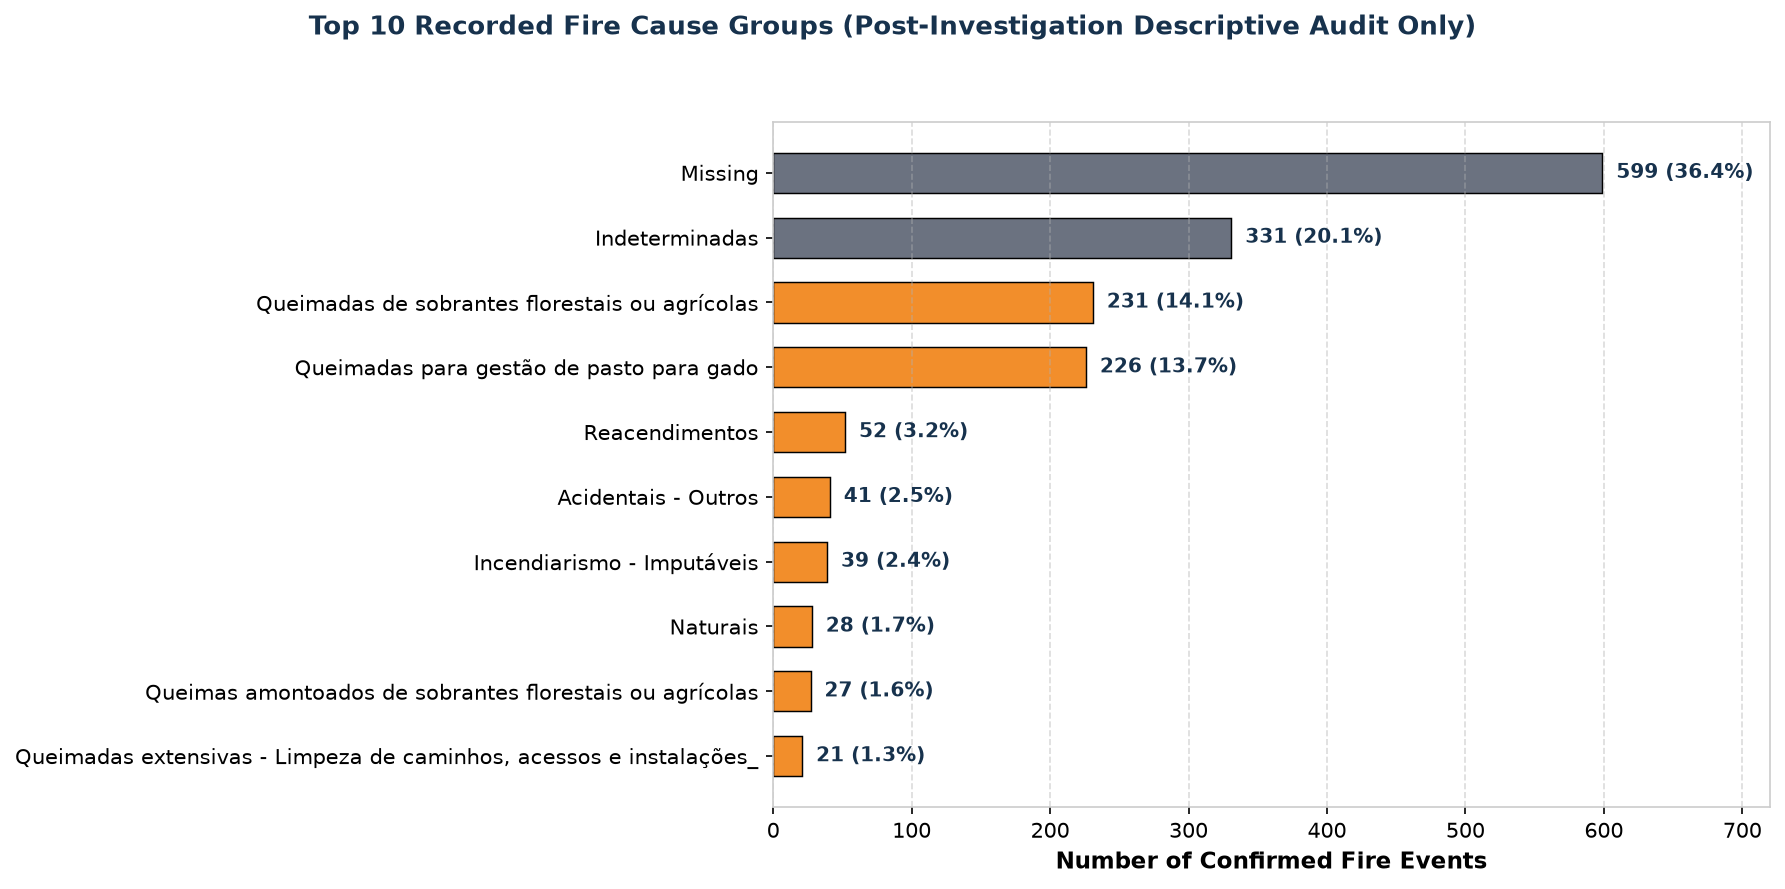


Saved Predictor-Time Audit table to: reports/tables/icnf_sgif/eda_predictor_time_audit.csv


,feature_group,examples,decision,reason
0,Calendar fields,"Ano, Mes, Dia, Hora",Candidate,Known at alert time; encode cyclically where appropriate.
1,Location,"X_ETRS89, Y_ETRS89, Concelho/Freguesia",Candidate,Known at alert time; test robust spatial encoding.
2,FWI family,"FFMC, DMC, DC, ISI, BUI, FWI, DSR",Candidate,Available for nearly all events; three rows need an explicit missing-data rule.
3,Direct weather,"temperature, RH, wind, rain",Requires join,Absent from SGIF; obtain from a documented historical weather source.
4,Cause,"CodCausa, TipoCausa, GrupoCausa, DescricaoCausa",Exclude by default,Often assigned after investigation and 36.44% missing at group level.
5,Response/outcome,"first intervention, extinction, duration, area components, class",Exclude,Known during/after the fire and directly leaks the final outcome.
6,Source/audit,"workbook, sheet, row, quality flags",Exclude,"Provenance fields, not physical prediction inputs."


In [11]:
# 1. Recorded Cause Group Summary (eda_cause_summary.csv)
df_cause = df["GrupoCausa"].fillna("Missing")
unique_causes = df_cause.unique()

cause_rows = []
for cause_label in unique_causes:
    c_sub = df[df_cause == cause_label]
    c_area = c_sub["AreaTotal_ha"]
    cause_rows.append({
        "GrupoCausa": cause_label,
        "records": int(len(c_sub)),
        "total_area_ha": float(c_area.sum()),
        "median_area_ha": float(c_area.median()),
        "maximum_area_ha": float(c_area.max()),
        "percentage": (len(c_sub) / len(df)) * 100.0,
    })

cause_summary = pd.DataFrame(cause_rows).sort_values("records", ascending=False).reset_index(drop=True)
cause_table_path = TABLE_DIR / "eda_cause_summary.csv"
cause_summary.to_csv(cause_table_path, index=False)
print(f"Saved post-ignition cause summary table to: {cause_table_path.as_posix()}")
print()
display(cause_summary.head(10))

# 2. Descriptive Audit of Post-Ignition Duration and Vegetation Land-Cover Sub-Areas
valid_duration = pd.to_numeric(df["Duracao_Horas"], errors="coerce").dropna()
fires_over_24h = int((pd.to_numeric(df["IncSup24horas"], errors="coerce") == 1).sum())

shrub_ha = float(df["AreaMato_ha"].sum())
forest_ha = float(df["AreaPov_ha"].sum())
agric_ha = float(df["AreaAgric_ha"].sum())
total_ha = float(df["AreaTotal_ha"].sum())

print("======================================================================")
print("POST-IGNITION OUTCOME AUDIT (HISTORICAL CONTEXT ONLY — NOT PREDICTORS)")
print("======================================================================")
print(f"Fire Duration (n = {len(valid_duration):,} valid) : Median = {valid_duration.median():.2f} h | Mean = {valid_duration.mean():.2f} h | Max = {valid_duration.max():.2f} h")
print(f"Fires Burning > 24 Hours (IncSup24horas) : {fires_over_24h} events ({fires_over_24h / len(df) * 100:.2f}%)")
print(f"Shrubland Burned (AreaMato_ha)           : {shrub_ha:,.2f} ha ({shrub_ha / total_ha * 100:.2f}% of total area)")
print(f"Forest/Woodland Burned (AreaPov_ha)      : {forest_ha:,.2f} ha ({forest_ha / total_ha * 100:.2f}% of total area)")
print(f"Agricultural Burned (AreaAgric_ha)       : {agric_ha:,.2f} ha ({agric_ha / total_ha * 100:.2f}% of total area)")
print("======================================================================")
print()

# --- Plot Top 10 Recorded Cause Groups (recorded_cause_groups.png) ---
# Sort ascending so the largest bar appears at the top of the horizontal bar chart
cause_top10 = cause_summary.head(10).sort_values("records", ascending=True).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(12, 6))

cause_colors = []
for cause_name in cause_top10["GrupoCausa"]:
    if cause_name in ["Missing", "Indeterminadas"]:
        cause_colors.append(GREY)
    else:
        cause_colors.append(ORANGE)

bars_c = ax.barh(
    cause_top10["GrupoCausa"],
    cause_top10["records"],
    color=cause_colors,
    edgecolor="black",
    linewidth=0.7,
    height=0.62,
)

fig.suptitle("Top 10 Recorded Fire Cause Groups (Post-Investigation Descriptive Audit Only)", fontsize=12.5, fontweight="bold", color=NAVY, y=0.98)
ax.set_xlabel("Number of Confirmed Fire Events", fontsize=11, fontweight="bold")
ax.set_xlim(0, 720)
ax.grid(axis="x", linestyle="--", alpha=0.45)

for bar, (_, row) in zip(bars_c, cause_top10.iterrows()):
    cnt = int(row["records"])
    pct = float(row["percentage"])
    ax.text(bar.get_width() + 10, bar.get_y() + bar.get_height() / 2, f"{cnt:,} ({pct:.1f}%)", va="center", ha="left", fontsize=9.5, fontweight="bold", color=NAVY)

plt.tight_layout(rect=[0, 0, 1, 0.94])
cause_fig_path = FIGURE_DIR / "recorded_cause_groups.png"
plt.savefig(cause_fig_path, dpi=300)
print(f"Saved recorded cause groups chart to: {cause_fig_path.as_posix()}")
plt.show()

# 3. Predictor-Time Feature Eligibility Audit Table (eda_predictor_time_audit.csv)
feature_audit = pd.DataFrame([
    ["Calendar fields", "Ano, Mes, Dia, Hora", "Candidate", "Known at alert time; encode cyclically where appropriate."],
    ["Location", "X_ETRS89, Y_ETRS89, Concelho/Freguesia", "Candidate", "Known at alert time; test robust spatial encoding."],
    ["FWI family", "FFMC, DMC, DC, ISI, BUI, FWI, DSR", "Candidate", "Available for nearly all events; three rows need an explicit missing-data rule."],
    ["Direct weather", "temperature, RH, wind, rain", "Requires join", "Absent from SGIF; obtain from a documented historical weather source."],
    ["Cause", "CodCausa, TipoCausa, GrupoCausa, DescricaoCausa", "Exclude by default", "Often assigned after investigation and 36.44% missing at group level."],
    ["Response/outcome", "first intervention, extinction, duration, area components, class", "Exclude", "Known during/after the fire and directly leaks the final outcome."],
    ["Source/audit", "workbook, sheet, row, quality flags", "Exclude", "Provenance fields, not physical prediction inputs."],
], columns=["feature_group", "examples", "decision", "reason"])

audit_table_path = TABLE_DIR / "eda_predictor_time_audit.csv"
feature_audit.to_csv(audit_table_path, index=False)
print()
print(f"Saved Predictor-Time Audit table to: {audit_table_path.as_posix()}")
display(feature_audit)


## Section 11: Automated Saved-File Verification

In [12]:
expected_tables = [
    "eda_target_summary.csv",
    "eda_fire_size_groups.csv",
    "eda_year_summary.csv",
    "eda_month_summary.csv",
    "eda_fwi_target_correlations.csv",
    "eda_fwi_summary.csv",
    "eda_cause_summary.csv",
    "eda_location_summary.csv",
    "eda_period_comparison.csv",
    "eda_extreme_fires_top20.csv",
    "eda_predictor_time_audit.csv",
]

expected_figures = [
    "burned_area_log1p_distribution.png",
    "fire_size_group_distribution.png",
    "montesinho_events_by_year_eda.png",
    "montesinho_total_area_by_year.png",
    "montesinho_events_by_month.png",
    "fwi_spearman_correlations.png",
    "recorded_cause_groups.png",
    "montesinho_burned_area_spatial_distribution.png",
]

verification_rows = []
for filename in expected_tables:
    rel_path = TABLE_DIR / filename
    verification_rows.append({
        "type": "table",
        "relative_path": rel_path.as_posix(),
        "exists": rel_path.exists(),
        "bytes": rel_path.stat().st_size if rel_path.exists() else 0,
    })

for filename in expected_figures:
    rel_path = FIGURE_DIR / filename
    verification_rows.append({
        "type": "figure",
        "relative_path": rel_path.as_posix(),
        "exists": rel_path.exists(),
        "bytes": rel_path.stat().st_size if rel_path.exists() else 0,
    })

verification_df = pd.DataFrame(verification_rows)
display(verification_df)
print()
print(f"Verified {len(expected_tables)} report tables and {len(expected_figures)} figures on disk.")


,type,relative_path,exists,bytes
0,table,reports/tables/icnf_sgif/eda_target_summary.csv,True,319
1,table,reports/tables/icnf_sgif/eda_fire_size_groups.csv,True,258
2,table,reports/tables/icnf_sgif/eda_year_summary.csv,True,1377
3,table,reports/tables/icnf_sgif/eda_month_summary.csv,True,817
4,table,reports/tables/icnf_sgif/eda_fwi_target_correlations.csv,True,439
5,table,reports/tables/icnf_sgif/eda_fwi_summary.csv,True,586
6,table,reports/tables/icnf_sgif/eda_cause_summary.csv,True,1675
7,table,reports/tables/icnf_sgif/eda_location_summary.csv,True,3527
8,table,reports/tables/icnf_sgif/eda_period_comparison.csv,True,344
9,table,reports/tables/icnf_sgif/eda_extreme_fires_top20.csv,True,5685



Verified 11 report tables and 8 figures on disk.
